# 固有値問題はなぜPCA・振動解析・量子力学・グラフに現れるのか

## 概要

固有値問題は線形な作用を独立な成分に分ける。PCA、振動、量子状態の時間発展、グラフ上の滑らかさから式を導き、Pythonで確認する。

## 実行環境

仮想環境は `wa-src(3.14.6)`、Pythonは `3.14.6` である。ライブラリのバージョンを次に示す。セルは上から実行する。小数は表示時だけ有効数字3桁にする。図はSVGで表示し、作業ディレクトリの `102_nb_files` に保存する。

In [1]:
import platform
import sys
from pathlib import Path
from pprint import pprint

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import scipy
import sympy as sp
from IPython.display import Math, display
from matplotlib.ticker import FuncFormatter
from matplotlib_inline.backend_inline import set_matplotlib_formats
from scipy.linalg import eigh

%matplotlib inline

# 実行中のPythonと仮想環境を確認する。
assert sys.version_info[:3] == (3, 14, 6)
assert sys.prefix != sys.base_prefix
print(f"実行環境: wa-src({platform.python_version()})")
print(f"Python: {sys.executable}")
print(f"OS: {platform.system()} {platform.release()}")
print(f"NumPy: {np.__version__}, SciPy: {scipy.__version__}")
print(f"Matplotlib: {matplotlib.__version__}, SymPy: {sp.__version__}")

# 配列と目盛の表示だけを3桁にする。図中の文字は可搬性を優先して英語にする。
np.set_printoptions(formatter={"float_kind": lambda value: f"{value:#.3g}"})
set_matplotlib_formats("svg")
plt.rcParams.update({
    "font.size": 11,
    "axes.grid": True,
    "grid.alpha": 0.200,
    "figure.figsize": (9, 4),
    "svg.fonttype": "none",
    "svg.hashsalt": "eigen-102",
})
figure_dir = Path("102_nb_files")
figure_dir.mkdir(parents=True, exist_ok=True)
colors = ["#2463a6", "#d05b30", "#2b856a"]


def save_figure(fig, name):
    """連続値の目盛を整え、SVGの保存と表示を行う。"""
    for ax in fig.axes:
        for axis in (ax.xaxis, ax.yaxis):
            # PC番号など、明示したカテゴリ名はそのまま残す。
            if not isinstance(axis.get_major_formatter(), FuncFormatter):
                axis.set_major_formatter(
                    FuncFormatter(lambda value, position: f"{value:#.3g}")
                )
    fig.savefig(figure_dir / name, format="svg", bbox_inches="tight",
                metadata={"Date": None})
    display(fig)
    plt.close(fig)

実行環境: wa-src(3.14.6)
Python: /Users/hiroshi/private/wa_src/.venv/bin/python
OS: Darwin 25.5.0
NumPy: 2.5.4, SciPy: 1.18.1
Matplotlib: 3.11.2, SymPy: 1.14.0


## 1. 固有ベクトルによる分解

$\mathbf{A}\mathbf{v}=\lambda\mathbf{v}$、$\mathbf{v}\ne\mathbf{0}$ は、作用後も同じ直線上に残る方向を表す。実対称行列の正規直交固有ベクトルを列に並べた行列を $\mathbf{Q}$、固有値の対角行列を $\mathbf{D}$ とすると、

$$
\begin{aligned}
\mathbf{A}\mathbf{Q}&=\mathbf{Q}\mathbf{D},\quad
\mathbf{Q}^{T}\mathbf{Q}=\mathbf{I},\\
\mathbf{A}&=\mathbf{Q}\mathbf{D}\mathbf{Q}^{T},\\
\mathbf{x}=\mathbf{Q}\mathbf{c}
&\Longrightarrow\mathbf{Q}^{T}\mathbf{A}\mathbf{x}=\mathbf{D}\mathbf{c}.
\end{aligned}
$$

$\mathbf{A}=\begin{pmatrix}2&1\\1&2\end{pmatrix}$ の特性方程式を次のセルで計算する。固有値3では $-v_1+v_2=0$、1では $v_1+v_2=0$ となり、規格化した固有ベクトルは $(1,1)^T/\sqrt2$ と $(1,-1)^T/\sqrt2$ である。

<IPython.core.display.Math object>

{'eigenvalues': array([1.00, 3.00]),
 'eigenvectors (columns)': array([[-0.707, 0.707],
       [0.707, 0.707]])}


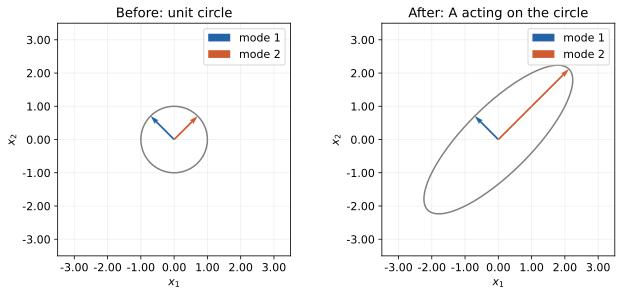

In [2]:
# 特性多項式は記号計算でも確かめる。
lam = sp.Symbol("lambda")
A_exact = sp.Matrix([[2, 1], [1, 2]])
polynomial = (A_exact - lam * sp.eye(2)).det()
display(Math(r"\det(\mathbf{A}-\lambda\mathbf{I})=(2-\lambda)^2-1="
             + sp.latex(sp.expand(polynomial))
             + "=" + sp.latex(sp.factor(polynomial)) + "=0"))

A = np.array(A_exact, dtype=float)
values, vectors = np.linalg.eigh(A)
pprint({"eigenvalues": values, "eigenvectors (columns)": vectors})

# 単位円と変換後の楕円に、固有ベクトルの方向を重ねる。
theta = np.linspace(0, 2 * np.pi, 361)
circle = np.array([np.cos(theta), np.sin(theta)])
fig, axes = plt.subplots(1, 2, figsize=(9, 4), layout="constrained")
for ax, points, scales, title in zip(
    axes, [circle, A @ circle], [np.ones(2), values],
    ["Before: unit circle", "After: A acting on the circle"],
):
    ax.plot(*points, color="0.500")
    for j in range(2):
        arrow = scales[j] * vectors[:, j]
        ax.quiver(0, 0, *arrow, angles="xy", scale_units="xy", scale=1,
                  color=colors[j], label=f"mode {j + 1}")
    ax.set(xlim=(-3.50, 3.50), ylim=(-3.50, 3.50),
           xlabel=r"$x_1$", ylabel=r"$x_2$", title=title)
    ax.set_aspect("equal")
    ax.legend()
save_figure(fig, "01_eigenvectors.svg")

## 2. PCA：分散の最大化

列ごとに平均を引いたデータを $\mathbf{X}\in\mathbb{R}^{n\times p}$、単位方向を $\mathbf{v}$ とする。射影後の平均も0なので、

$$
\mathbf{S}=\frac{\mathbf{X}^{T}\mathbf{X}}{n-1},\quad
\mathbf{z}=\mathbf{X}\mathbf{v},\quad
\frac{\mathbf{z}^{T}\mathbf{z}}{n-1}
=\frac{\mathbf{v}^{T}\mathbf{X}^{T}\mathbf{X}\mathbf{v}}{n-1}
=\mathbf{v}^{T}\mathbf{S}\mathbf{v}.
$$

制約 $\mathbf{v}^{T}\mathbf{v}=1$ をラグランジュ乗数で加えると、

$$
\begin{aligned}
F&=\mathbf{v}^{T}\mathbf{S}\mathbf{v}-\lambda(\mathbf{v}^{T}\mathbf{v}-1),\\
\nabla_{\mathbf{v}}F&=2\mathbf{S}\mathbf{v}-2\lambda\mathbf{v}=\mathbf{0}.
\end{aligned}
$$

<div>
$$\boxed{\mathbf{S}\mathbf{v}=\lambda\mathbf{v},\quad
\mathbf{v}^{T}\mathbf{S}\mathbf{v}=\lambda}$$
</div>

最大固有値の方向が第1主成分である。残りは直交する方向から順に選ぶ。ここでは同じ単位の2変数を使う。尺度が異なる場合は標準化の要否を決める。[MITのPCA講義](https://ocw.mit.edu/courses/9-641j-introduction-to-neural-networks-spring-2005/resources/lec18_pca/)

{'eigenvalues': array([3.01, 0.991]),
 'explained variance ratio': array([0.752, 0.248]),
 'sample covariance': array([[2.00, 1.01],
       [1.01, 1.99]])}


<IPython.core.display.Math object>

<IPython.core.display.Math object>

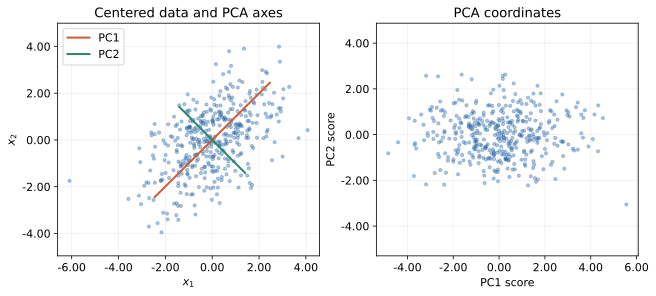

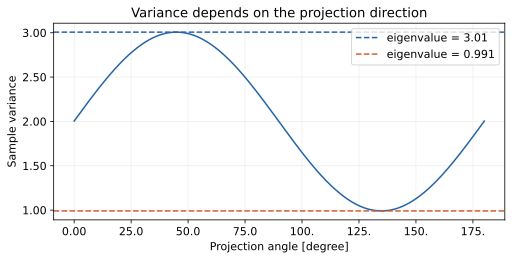

In [3]:
# 相関のある2変数を生成し、標本平均を引く。
rng = np.random.default_rng(102)
X = rng.multivariate_normal([0, 0], [[2, 1], [1, 2]], size=400)
X -= X.mean(axis=0)
S = X.T @ X / (len(X) - 1)
pca_values, pca_vectors = np.linalg.eigh(S)
order = np.argsort(pca_values)[::-1]
pca_values, pca_vectors = pca_values[order], pca_vectors[:, order]
scores = X @ pca_vectors
explained = pca_values / pca_values.sum()
pprint({"sample covariance": S, "eigenvalues": pca_values,
        "explained variance ratio": explained})
display(Math(r"\operatorname{Var}(z_1)=" + f"{pca_values[0]:#.3g}"
             + r",\quad\operatorname{Var}(z_2)=" + f"{pca_values[1]:#.3g}"))
# 固有基底の係数a_iで書けば、最大固有値が分散の上限になる。
display(Math(r"\mathbf{v}=\mathbf{Q}\mathbf{a},\quad\sum_i a_i^2=1,\quad"
             r"\mathbf{v}^{T}\mathbf{S}\mathbf{v}=\sum_i\lambda_i a_i^2"
             r"\le\lambda_{\max}\sum_i a_i^2=\lambda_{\max}"))

fig, axes = plt.subplots(1, 2, figsize=(9, 4), layout="constrained")
axes[0].scatter(*X.T, s=10, alpha=0.350, color=colors[0])
for j in range(2):
    direction = 2 * np.sqrt(pca_values[j]) * pca_vectors[:, j]
    axes[0].plot([-direction[0], direction[0]],
                 [-direction[1], direction[1]], color=colors[j + 1],
                 lw=2, label=f"PC{j + 1}")
axes[0].set(xlabel=r"$x_1$", ylabel=r"$x_2$", title="Centered data and PCA axes")
axes[0].legend()
axes[1].scatter(*scores.T, s=10, alpha=0.350, color=colors[0])
axes[1].set(xlabel="PC1 score", ylabel="PC2 score", title="PCA coordinates")
for ax in axes:
    ax.set_aspect("equal", adjustable="datalim")
save_figure(fig, "02_pca_coordinates.svg")

# 方向を回して分散を計算し、最大値と固有値を比較する。
angles = np.linspace(0, np.pi, 361)
directions = np.array([np.cos(angles), np.sin(angles)])
variance = np.sum(directions * (S @ directions), axis=0)
fig, ax = plt.subplots(figsize=(7, 3.50), layout="constrained")
ax.plot(np.degrees(angles), variance, color=colors[0])
for value, color in zip(pca_values, colors):
    ax.axhline(value, color=color, ls="--", label=f"eigenvalue = {value:#.3g}")
ax.set(xlabel="Projection angle [degree]", ylabel="Sample variance",
       title="Variance depends on the projection direction")
ax.legend()
save_figure(fig, "03_pca_variance.svg")

私は、散布図と分散の曲線を並べると、最大化の意味を確認しやすいと感じる。

## 3. 振動解析：振動モード

壁と2個の質点を3本のばねでつなぐ。ばね定数を1、質量を1と2とする。単位はそろえ、減衰と外力はない。

$$
\ddot{x}_1=-x_1+(x_2-x_1),\quad
2\ddot{x}_2=-(x_2-x_1)-x_2,
$$
$$
\mathbf{M}\ddot{\mathbf{x}}+\mathbf{K}\mathbf{x}=\mathbf{0},\quad
\mathbf{M}=\begin{pmatrix}1&0\\0&2\end{pmatrix},\quad
\mathbf{K}=\begin{pmatrix}2&-1\\-1&2\end{pmatrix}.
$$

$\mathbf{x}(t)=\mathbf{v}\cos(\omega t)$ を代入すると、$\ddot{\mathbf{x}}=-\omega^2\mathbf{v}\cos(\omega t)$ より、

<div>
$$\boxed{\mathbf{K}\mathbf{v}=\omega^2\mathbf{M}\mathbf{v}}$$
</div>

固有値は角振動数の二乗である。$\lambda=\omega^2$ として、

$$
\det(\mathbf{K}-\lambda\mathbf{M})
=(2-\lambda)(2-2\lambda)-1
=2\lambda^2-6\lambda+3=0,\quad
\lambda=\frac{6\pm\sqrt{36-24}}4=\frac{3\pm\sqrt3}2.
$$

第1行から $v_2=(2-\lambda)v_1$ を得る。$\mathbf{V}^{T}\mathbf{M}\mathbf{V}=\mathbf{I}$ と規格化し、$\mathbf{x}=\mathbf{V}\mathbf{q}$ を代入して左から $\mathbf{V}^{T}$ を掛けると、$\ddot{\mathbf{q}}+\mathbf{D}\mathbf{q}=\mathbf{0}$ となる。各成分は独立した振動になる。[MITの振動講義](https://ocw.mit.edu/ans7870/18/18.013a/textbook/HTML/chapter32/section09.html)

{'angular frequency': array([0.796, 1.54]),
 'mass-normalized modes': array([[-0.460, -0.888],
       [-0.628, 0.325]]),
 'omega squared': array([0.634, 2.37])}


<IPython.core.display.Math object>

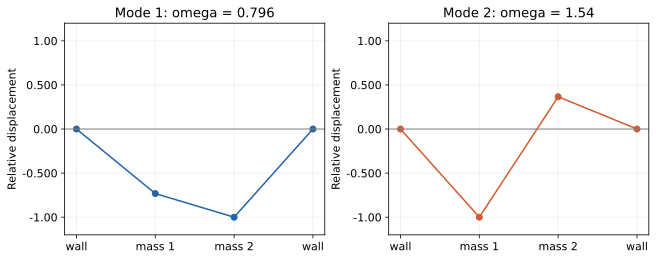

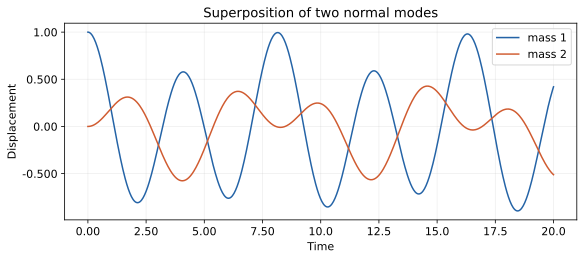

In [4]:
M = np.diag([1, 2])
K = np.array([[2, -1], [-1, 2]])

# 一般化固有値問題を直接解く。列ベクトルは質量行列で規格化される。
omega2, modes = eigh(K, M)
omega = np.sqrt(omega2)
pprint({"omega squared": omega2, "angular frequency": omega,
        "mass-normalized modes": modes})
display(Math(r"\omega_1=" + f"{omega[0]:#.3g}"
             + r",\quad\omega_2=" + f"{omega[1]:#.3g}"))

fig, axes = plt.subplots(1, 2, figsize=(9, 3.50), layout="constrained")
for j, ax in enumerate(axes):
    shape = modes[:, j] / np.max(np.abs(modes[:, j]))
    ax.plot([0, 1, 2, 3], [0, *shape, 0], "o-", color=colors[j])
    ax.axhline(0, color="0.500", lw=1)
    ax.set(xticks=[0, 1, 2, 3], xticklabels=["wall", "mass 1", "mass 2", "wall"],
           ylim=(-1.20, 1.20), ylabel="Relative displacement",
           title=f"Mode {j + 1}: omega = {omega[j]:#.3g}")
save_figure(fig, "04_vibration_modes.svg")

# 初期変位(1, 0)、初速度0をモードに分解して時間発展させる。
t_vibration = np.linspace(0, 20, 600)
x_initial = np.array([1, 0])
q_initial = modes.T @ M @ x_initial
q = q_initial[:, None] * np.cos(omega[:, None] * t_vibration)
q_dot = -omega[:, None] * q_initial[:, None] * np.sin(omega[:, None] * t_vibration)
x = modes @ q
x_dot = modes @ q_dot
fig, ax = plt.subplots(figsize=(8, 3.50), layout="constrained")
for j in range(2):
    ax.plot(t_vibration, x[j], color=colors[j], label=f"mass {j + 1}")
ax.set(xlabel="Time", ylabel="Displacement", title="Superposition of two normal modes")
ax.legend()
save_figure(fig, "05_vibration_time.svg")

## 4. 量子力学：エネルギー固有状態

二状態系の振幅ベクトルを $\mathbf{c}(t)$ とする。時間に依存しないエルミート行列 $\mathbf{H}$ に対して、シュレーディンガー方程式に $\mathbf{c}(t)=\mathbf{v}e^{-iEt/\hbar}$ を代入する。

$$
i\hbar\dot{\mathbf{c}}=\mathbf{H}\mathbf{c},\quad
i\hbar\left(-\frac{iE}{\hbar}\right)\mathbf{v}e^{-iEt/\hbar}
=\mathbf{H}\mathbf{v}e^{-iEt/\hbar}.
$$

<div>
$$\boxed{\mathbf{H}\mathbf{v}=E\mathbf{v}}$$
</div>

固有値はエネルギーである。$\mathbf{H}=g\begin{pmatrix}0&1\\1&0\end{pmatrix}$、$g>0$ なら、$\det(\mathbf{H}-E\mathbf{I})=E^2-g^2=0$ より $E_\pm=\pm g$、$\mathbf{v}_\pm=(1,\pm1)^T/\sqrt2$ となる。

初期状態 $(1,0)^T=(\mathbf{v}_++\mathbf{v}_-)/\sqrt2$ から、$\tau=gt/\hbar$ とおくと、

$$
\begin{aligned}
\mathbf{c}(t)&=\frac{\mathbf{v}_+e^{-i\tau}+\mathbf{v}_-e^{i\tau}}{\sqrt2}
=\frac12\begin{pmatrix}e^{-i\tau}+e^{i\tau}\\e^{-i\tau}-e^{i\tau}\end{pmatrix}
=\begin{pmatrix}\cos\tau\\-i\sin\tau\end{pmatrix},\\
P_1&=|c_1|^2=\cos^2\tau,\quad P_2=|c_2|^2=\sin^2\tau.
\end{aligned}
$$

固有状態では全体の位相だけが変わり、各基底状態の確率は一定である。重ね合わせでは相対位相が変わり、確率が振動する。[MITの二状態系の資料](https://ocw.mit.edu/courses/6-728-applied-quantum-and-statistical-physics-fall-2006/resources/twolevel04/)

{'E / g': array([-1.00, 1.00]),
 'energy eigenstates (columns)': array([[-0.707, 0.707],
       [0.707, 0.707]])}


<IPython.core.display.Math object>

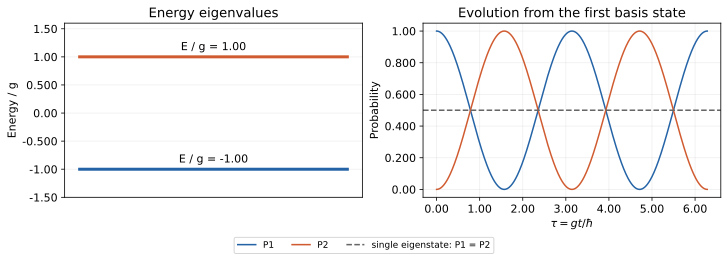

In [5]:
# エネルギーをg、時間をhbar/gで測った無次元の行列を使う。
H = np.array([[0, 1], [1, 0]])
energies, states = np.linalg.eigh(H)
tau = np.linspace(0, 2 * np.pi, 500)
c_initial = np.array([1, 0])
coefficients = states.conj().T @ c_initial
phases = np.exp(-1j * energies[:, None] * tau)
c = states @ (coefficients[:, None] * phases)
probabilities = np.abs(c) ** 2
pprint({"E / g": energies, "energy eigenstates (columns)": states})
display(Math(r"P_1+P_2=\cos^2\tau+\sin^2\tau=1"))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.50), layout="constrained")
for j in range(2):
    axes[0].hlines(energies[j], 0, 1, color=colors[j], lw=3)
    axes[0].text(0.500, energies[j] + 0.120, f"E / g = {energies[j]:#.3g}", ha="center")
axes[0].set(xticks=[], ylim=(-1.50, 1.60), ylabel="Energy / g", title="Energy eigenvalues")
for j in range(2):
    axes[1].plot(tau, probabilities[j], color=colors[j], label=f"P{j + 1}")
# 単一のエネルギー固有状態ではP1=P2=1/2のままである。
axes[1].axhline(1 / 2, color="0.400", ls="--", label="single eigenstate: P1 = P2")
axes[1].set(xlabel=r"$\tau = gt/\hbar$", ylabel="Probability", ylim=(-0.0500, 1.05),
           title="Evolution from the first basis state")
fig.legend(*axes[1].get_legend_handles_labels(), loc="outside lower center", ncol=3, fontsize=9)
save_figure(fig, "06_quantum_states.svg")

## 5. グラフ：隣接頂点の値の差

無向グラフの重みを $w_{ij}=w_{ji}\ge0$、次数を $d_i=\sum_jw_{ij}$ とする。隣接行列 $\mathbf{W}$、次数行列 $\mathbf{D}_g$ から $\mathbf{L}=\mathbf{D}_g-\mathbf{W}$ を作ると、

$$
\begin{aligned}
\mathbf{f}^{T}\mathbf{L}\mathbf{f}
&=\sum_i d_i f_i^2-\sum_{i,j}w_{ij}f_if_j\\
&=\frac12\sum_{i,j}w_{ij}(f_i^2+f_j^2-2f_if_j)\\
&=\sum_{i<j}w_{ij}(f_i-f_j)^2\ge0.
\end{aligned}
$$

定数ベクトルでは差が0なので $\mathbf{L}\mathbf{1}=\mathbf{0}$ である。連結グラフで $\mathbf{f}^{T}\mathbf{1}=0$、$\mathbf{f}^{T}\mathbf{f}=1$ を課し、この二次形式を最小化する。停留条件は $2\mathbf{L}\mathbf{f}-2\lambda\mathbf{f}-\mu\mathbf{1}=\mathbf{0}$ となる。左から $\mathbf{1}^{T}$ を掛けると $-\mu n=0$、したがって、

<div>
$$\boxed{\mathbf{L}\mathbf{f}=\lambda_2\mathbf{f}}$$
</div>

$\lambda_2$ は2番目に小さい固有値である。固有ベクトルの符号で弱くつながる集団を分けられる場合があるが、最適な離散分割とは限らない。[Spielmanの講義資料](https://www.cs.yale.edu/homes/spielman/eigs/lect2.pdf)

{'Fiedler vector': array([-0.425, -0.425, -0.373, 0.373, 0.425, 0.425]),
 'Laplacian': array([[2.00, -1.00, -1.00, 0.00, 0.00, 0.00],
       [-1.00, 2.00, -1.00, 0.00, 0.00, 0.00],
       [-1.00, -1.00, 2.20, -0.200, 0.00, 0.00],
       [0.00, 0.00, -0.200, 2.20, -1.00, -1.00],
       [0.00, 0.00, 0.00, -1.00, 2.00, -1.00],
       [0.00, 0.00, 0.00, -1.00, -1.00, 2.00]]),
 'eigenvalues': array([2.99e-16, 0.122, 3.00, 3.00, 3.00, 3.28])}


<IPython.core.display.Math object>

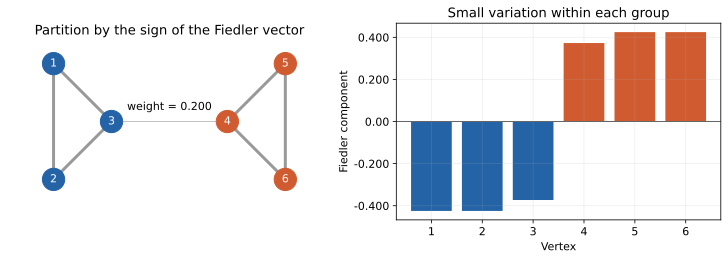

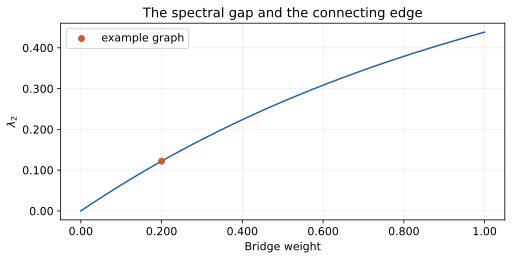

In [6]:
# 3頂点の完全グラフを2個作り、1本の弱い辺でつなぐ。
W = np.zeros((6, 6))
for group in ([0, 1, 2], [3, 4, 5]):
    for i in group:
        for j in group:
            if i != j:
                W[i, j] = 1
W[2, 3] = W[3, 2] = 0.200
L = np.diag(W.sum(axis=1)) - W
graph_values, graph_vectors = np.linalg.eigh(L)
fiedler = graph_vectors[:, 1]
# 固有ベクトルの符号は任意なので、図では最初の成分を負にそろえる。
if fiedler[0] > 0:
    fiedler = -fiedler
# 理論上の零固有値も、浮動小数点計算では微小な値になることがある。
pprint({"Laplacian": L, "eigenvalues": graph_values,
        "Fiedler vector": fiedler})
display(Math(r"\lambda_2=" + f"{graph_values[1]:#.3g}"))

positions = np.array([[0, 1], [0, -1], [1, 0], [3, 0], [4, 1], [4, -1]])
fig, axes = plt.subplots(1, 2, figsize=(10, 3.50), layout="constrained")
for i in range(6):
    for j in range(i + 1, 6):
        if W[i, j] > 0:
            axes[0].plot(*positions[[i, j]].T, color="0.600", lw=3 * W[i, j])
node_colors = [colors[0] if value < 0 else colors[1] for value in fiedler]
axes[0].scatter(*positions.T, c=node_colors, s=500, zorder=3)
for i, point in enumerate(positions):
    axes[0].text(*point, str(i + 1), ha="center", va="center", color="white", zorder=4)
axes[0].text(2, 0.200, "weight = 0.200", ha="center")
axes[0].set(title="Partition by the sign of the Fiedler vector", aspect="equal")
axes[0].set_axis_off()
axes[0].margins(0.200)
axes[1].bar(np.arange(1, 7), fiedler, color=node_colors)
axes[1].axhline(0, color="0.400", lw=1)
axes[1].set(xlabel="Vertex", ylabel="Fiedler component", title="Small variation within each group",
            xticks=np.arange(1, 7), xticklabels=[str(i) for i in range(1, 7)])
save_figure(fig, "07_graph_partition.svg")

# 橋の重みだけを変え、2番目の固有値がどう変わるか確かめる。
bridge_weights = np.linspace(0, 1, 101)
gaps = []
for weight in bridge_weights:
    W_trial = W.copy()
    W_trial[2, 3] = W_trial[3, 2] = weight
    L_trial = np.diag(W_trial.sum(axis=1)) - W_trial
    gaps.append(np.linalg.eigvalsh(L_trial)[1])
fig, ax = plt.subplots(figsize=(7, 3.50), layout="constrained")
ax.plot(bridge_weights, gaps, color=colors[0])
ax.scatter([W[2, 3]], [graph_values[1]], color=colors[1], label="example graph", zorder=3)
ax.set(xlabel="Bridge weight", ylabel=r"$\lambda_2$", title="The spectral gap and the connecting edge")
ax.legend()
save_figure(fig, "08_graph_gap.svg")

橋の重みが0では零固有値が2個になる。橋を強くすると $\lambda_2$ が増える。

## 6. 計算の確認

残差、射影分散、保存則、二次形式を確認する。

In [7]:
# 異なる式から同じ量を計算し、導出と実装の対応を確認する。
assert np.allclose(np.var(scores, axis=0, ddof=1), pca_values)
assert np.allclose(K @ modes, (M @ modes) * omega2)
assert np.allclose(modes.T @ M @ modes, np.eye(2))
expected_omega2 = (3 + np.array([-1, 1]) * np.sqrt(3)) / 2
assert np.allclose(omega2, expected_omega2)
assert np.allclose(x[:, 0], x_initial)
energy = (np.sum(x_dot * (M @ x_dot), axis=0)
          + np.sum(x * (K @ x), axis=0)) / 2
assert np.allclose(energy, energy[0])
assert np.allclose(probabilities.sum(axis=0), 1)
assert np.allclose(probabilities[0], np.cos(tau) ** 2)
edge_energy = sum(W[i, j] * (fiedler[i] - fiedler[j]) ** 2
                  for i in range(6) for j in range(i + 1, 6))
assert np.allclose(fiedler @ L @ fiedler, edge_energy)
assert np.isclose(fiedler.sum(), 0, atol=1.00e-12)
assert np.array_equal(fiedler < 0, [True, True, True, False, False, False])

residuals = {
    "PCA": np.linalg.norm(S @ pca_vectors - pca_vectors * pca_values),
    "vibration": np.linalg.norm(K @ modes - (M @ modes) * omega2),
    "quantum": np.linalg.norm(H @ states - states * energies),
    "graph": np.linalg.norm(L @ graph_vectors - graph_vectors * graph_values),
}
assert max(residuals.values()) < 1.00e-10
# 辞書の浮動小数点数も表示時だけ丸める。
pprint({name: f"{float(value):#.3g}" for name, value in residuals.items()})
print("固有方程式、保存則、解析解との一致を確認した。")

{'PCA': '1.57e-16',
 'graph': '2.14e-15',
 'quantum': '0.00',
 'vibration': '4.61e-16'}
固有方程式、保存則、解析解との一致を確認した。


## 結論

この記事では、PCA・振動解析・量子力学・グラフが固有値問題に至る理由を、最適化と時間発展の式から確認した。

固有値は順に分散、角振動数の二乗、エネルギー、グラフ上の変動の大きさを表す。適切な基底で成分を分離する計算は共通である。直交するモードを使えるのは、対称行列、エルミート行列、正定値の質量行列を扱ったためであり、一般の行列にはそのまま広げられない。